# PLN — Coleta, pré-processamento e representação de receitas do TudoGostoso

**Equipe:** Alana Cristina Andreazza, Beatriz Moresco Joaquim, Caio Abraão, Haiko Rudiger e Leticia Fruet

Este notebook realiza as seguintes etapas:

1. coleta paginada das receitas do TudoGostoso, mantendo os dados estruturados e utilizando checkpoint para permitir a continuidade da coleta;
2. organização, validação e exportação dos dados coletados em CSV e JSON;
3. pré-processamento textual seguindo a estrutura apresentada pelo professor;
4. representação dos textos utilizando Bag of Words (BoW), TF-IDF, Word2Vec e BERTimbau;
5. aplicação e comparação das representações em tarefas de similaridade, clusterização e busca de receitas.

A base mantém os campos estruturados de cada receita e cria também um campo textual consolidado para aplicação das técnicas de Processamento de Linguagem Natural. Os dados processados e exportados por este notebook também servem como entrada para as etapas posteriores do projeto, como a classificação de receitas.

## 1. Preparação do ambiente

Para a coleta são utilizados `requests` e `BeautifulSoup`.  
Para o pré-processamento, seguimos as bibliotecas utilizadas no notebook do professor:

- **NLTK**: tokenização, stopwords e stemming;
- **spaCy**: lematização;
- **Pandas**: organização dos dados.

In [ ]:
%pip -q install requests beautifulsoup4 pandas nltk spacy

In [ ]:
import re
import subprocess
import sys
import time

import nltk
import pandas as pd
import requests
import spacy

from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
from nltk.tokenize import word_tokenize
from urllib.parse import urljoin

for recurso in ["punkt", "punkt_tab", "stopwords", "rslp"]:
    nltk.download(recurso, quiet=True)

try:
    nlp = spacy.load("pt_core_news_sm")
except OSError:
    subprocess.run(
        [sys.executable, "-m", "spacy", "download", "pt_core_news_sm"],
        check=True,
    )
    nlp = spacy.load("pt_core_news_sm")

print("Ambiente preparado com sucesso.")

Ambiente preparado com sucesso.


## 2. Categorias utilizadas

Foram mantidas as categorias definidas pelo grupo para obter variedade de receitas.

In [ ]:
BASE_URL = "https://www.tudogostoso.com.br"

CATEGORIAS = [
    {"categoria": "BOLOS E TORTAS", "url": "https://www.tudogostoso.com.br/categorias/1000-bolos-e-tortas-doces"},
    {"categoria": "CARNES", "url": "https://www.tudogostoso.com.br/categorias/1004-carnes"},
    {"categoria": "AVES", "url": "https://www.tudogostoso.com.br/categorias/1009-aves"},
    {"categoria": "PEIXES E FRUTOS DO MAR", "url": "https://www.tudogostoso.com.br/categorias/1014-peixes-e-frutos-do-mar"},
    {"categoria": "SALADAS E MOLHOS", "url": "https://www.tudogostoso.com.br/categorias/1023-saladas-molhos-e-acompanhamentos"},
    {"categoria": "SOPAS", "url": "https://www.tudogostoso.com.br/categorias/1027-sopas"},
    {"categoria": "MASSAS", "url": "https://www.tudogostoso.com.br/categorias/1028-massas"},
    {"categoria": "BEBIDAS", "url": "https://www.tudogostoso.com.br/categorias/1032-bebidas"},
    {"categoria": "DOCES E SOBREMESAS", "url": "https://www.tudogostoso.com.br/categorias/1037-doces-e-sobremesas"},
    {"categoria": "LANCHES", "url": "https://www.tudogostoso.com.br/categorias/1044-lanches"},
    {"categoria": "ALIMENTAÇÃO SAUDÁVEL", "url": "https://www.tudogostoso.com.br/categorias/1334-alimentacao-saudavel"},
]

# Quantidade total desejada por categoria, considerando todas as páginas.
# O TudoGostoso exibe aproximadamente 15 receitas por página nessa listagem.
LIMITE_RECEITAS_POR_CATEGORIA = 60

# Proteção para impedir uma coleta sem limite caso a estrutura do site mude.
MAX_PAGINAS_POR_CATEGORIA = 10

# Pequena pausa entre páginas de listagem.
INTERVALO_ENTRE_PAGINAS = 0.5


## 3. Acesso às páginas

A estrutura anterior dependia de caminhos CSS longos e de posições como `nth-child`.  
Isso tornava a coleta sensível a pequenas mudanças no HTML.

Nesta versão, a extração usa principalmente classes e seções semânticas da página.  
A versão AMP oficial da mesma receita é usada somente como apoio para campos que podem não estar presentes de forma estável no HTML principal, como avaliação, dificuldade e custo.

In [ ]:
import random

sessao = requests.Session()
sessao.headers.update({
    "User-Agent": "FURB-PLN-AvaliacaoPratica1/1.0 (uso academico)",
    "Accept-Language": "pt-BR,pt;q=0.9",
})

MAX_TENTATIVAS_REQUISICAO = 4
ESPERA_INICIAL_429 = 30


class LimiteRequisicoesExcedido(Exception):
    pass


def obter_soup(url, max_tentativas=MAX_TENTATIVAS_REQUISICAO):
    for tentativa in range(max_tentativas):
        try:
            resposta = sessao.get(url, timeout=20)

            if resposta.status_code == 429:
                retry_after = resposta.headers.get("Retry-After")

                try:
                    espera = float(retry_after) if retry_after else None
                except (TypeError, ValueError):
                    espera = None

                if espera is None:
                    espera = ESPERA_INICIAL_429 * (2 ** tentativa)

                # Pequena variação evita fazer a nova tentativa exatamente
                # no mesmo instante em que o período de bloqueio termina.
                espera += random.uniform(0, 3)

                if tentativa < max_tentativas - 1:
                    print(
                        f"429 em {url}. "
                        f"Nova tentativa em {espera:.0f}s "
                        f"({tentativa + 1}/{max_tentativas - 1})."
                    )
                    time.sleep(espera)
                    continue

                raise LimiteRequisicoesExcedido(
                    f"Limite de requisições persistiu após "
                    f"{max_tentativas} tentativas: {url}"
                )

            # Erros temporários do servidor também podem ser tentados novamente.
            if 500 <= resposta.status_code < 600 and tentativa < max_tentativas - 1:
                espera = 5 * (2 ** tentativa)
                print(
                    f"Erro {resposta.status_code} em {url}. "
                    f"Nova tentativa em {espera}s."
                )
                time.sleep(espera)
                continue

            resposta.raise_for_status()
            return BeautifulSoup(resposta.content, "html.parser")

        except LimiteRequisicoesExcedido:
            raise
        except requests.RequestException as erro:
            if tentativa < max_tentativas - 1:
                espera = 5 * (2 ** tentativa)
                print(
                    f"Erro ao acessar {url}: {erro}. "
                    f"Nova tentativa em {espera}s."
                )
                time.sleep(espera)
                continue

            print(f"Erro ao acessar {url}: {erro}")
            return None

    return None


def url_amp(url):
    return url.replace(
        "https://www.tudogostoso.com.br/",
        "https://amp.tudogostoso.com.br/"
    )


## 4. Localização das receitas nas categorias

Primeiro reunimos os links de todas as categorias.

A URL é usada como identificador da receita. Se a mesma URL aparecer em duas ou mais categorias, ela permanece uma única vez e o campo `Categorias` recebe todas as categorias correspondentes.

In [ ]:
SELETOR_TITULOS_RECEITAS = (
    "#main-content div.mg-container.gd-2-cols div.left-col "
    "section.u-margin-top.u-padding-top.u-padding-bottom "
    "div.card-content h2 a"
)


def extrair_receitas_categoria(
    categoria,
    url_categoria,
    limite=None,
    max_paginas=10,
):
    receitas = []
    urls_encontradas = set()
    pagina = 1

    while pagina <= max_paginas:
        if limite is not None and len(receitas) >= limite:
            break

        url_pagina = (
            url_categoria
            if pagina == 1
            else f"{url_categoria}?page={pagina}"
        )

        soup = obter_soup(url_pagina)

        if soup is None:
            break

        elementos = soup.select(SELETOR_TITULOS_RECEITAS)

        if not elementos:
            print(
                f"{categoria}: nenhuma receita encontrada "
                f"na página {pagina}. Encerrando."
            )
            break

        novas_na_pagina = 0

        for elemento in elementos:
            href = elemento.get("href")

            if not href:
                continue

            url_receita = urljoin(BASE_URL, href)

            if url_receita in urls_encontradas:
                continue

            urls_encontradas.add(url_receita)
            receitas.append({
                "Título": elemento.get_text(" ", strip=True),
                "URL da receita": url_receita,
                "Categoria": categoria,
            })
            novas_na_pagina += 1

            if limite is not None and len(receitas) >= limite:
                break

        print(
            f"{categoria}: página {pagina} -> "
            f"{novas_na_pagina} novas receitas "
            f"({len(receitas)} acumuladas)"
        )

        # Se a página repetir somente receitas já vistas, evita loop infinito.
        if novas_na_pagina == 0:
            break

        pagina += 1
        time.sleep(INTERVALO_ENTRE_PAGINAS)

    return receitas


receitas_por_url = {}

for categoria in CATEGORIAS:
    encontradas = extrair_receitas_categoria(
        categoria["categoria"],
        categoria["url"],
        LIMITE_RECEITAS_POR_CATEGORIA,
        MAX_PAGINAS_POR_CATEGORIA,
    )

    for receita in encontradas:
        url = receita["URL da receita"]

        if url not in receitas_por_url:
            receitas_por_url[url] = {
                "Título": receita["Título"],
                "URL da receita": url,
                "Categorias": [],
            }

        if receita["Categoria"] not in receitas_por_url[url]["Categorias"]:
            receitas_por_url[url]["Categorias"].append(
                receita["Categoria"]
            )

print("\nReceitas únicas encontradas:", len(receitas_por_url))


BOLOS E TORTAS: página 1 -> 15 novas receitas (15 acumuladas)
BOLOS E TORTAS: página 2 -> 15 novas receitas (30 acumuladas)
BOLOS E TORTAS: página 3 -> 15 novas receitas (45 acumuladas)
BOLOS E TORTAS: página 4 -> 15 novas receitas (60 acumuladas)
CARNES: página 1 -> 15 novas receitas (15 acumuladas)
CARNES: página 2 -> 15 novas receitas (30 acumuladas)
CARNES: página 3 -> 15 novas receitas (45 acumuladas)
CARNES: página 4 -> 15 novas receitas (60 acumuladas)
AVES: página 1 -> 15 novas receitas (15 acumuladas)
AVES: página 2 -> 15 novas receitas (30 acumuladas)
AVES: página 3 -> 15 novas receitas (45 acumuladas)
AVES: página 4 -> 15 novas receitas (60 acumuladas)
PEIXES E FRUTOS DO MAR: página 1 -> 15 novas receitas (15 acumuladas)
PEIXES E FRUTOS DO MAR: página 2 -> 15 novas receitas (30 acumuladas)
PEIXES E FRUTOS DO MAR: página 3 -> 15 novas receitas (45 acumuladas)
PEIXES E FRUTOS DO MAR: página 4 -> 15 novas receitas (60 acumuladas)
SALADAS E MOLHOS: página 1 -> 15 novas receitas 

## 5. Extração dos dados da receita

- ingredientes são procurados dentro de `section.recipe-ingredients`;
- utensílios dentro de `section.recipe-equipments`;
- etapas são localizadas pelos IDs que começam com `recipe-step`;
- porções são obtidas pelo título da seção de ingredientes;
- avaliação, quantidade de avaliações, dificuldade e custo possuem fallback pela página AMP oficial.

In [ ]:
def texto_elemento(elemento):
    return elemento.get_text(" ", strip=True) if elemento else None


def limpar_texto_utensilio(texto):
    if not texto:
        return None

    texto = re.sub(r"\bComprar\b", "", texto, flags=re.IGNORECASE)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto or None


def extrair_porcoes(soup):
    secao = soup.select_one("section.recipe-ingredients")

    if secao:
        titulo = secao.find(["h1", "h2", "h3"])
        if titulo:
            texto = titulo.get_text(" ", strip=True)
            resultado = re.search(
                r"(\d+\s+porç(?:ão|ões))",
                texto,
                flags=re.IGNORECASE,
            )
            if resultado:
                return resultado.group(1)

    return None


def extrair_ingredientes(soup):
    secao = soup.select_one("section.recipe-ingredients")

    if not secao:
        return []

    ingredientes = []

    for item in secao.select("li"):
        texto = item.get_text(" ", strip=True)

        if texto:
            ingredientes.append(texto)

    return ingredientes


def extrair_utensilios(soup):
    secao = soup.select_one("section.recipe-equipments")

    if not secao:
        return []

    utensilios = []

    for item in secao.select("li"):
        texto = limpar_texto_utensilio(
            item.get_text(" ", strip=True)
        )

        if texto:
            utensilios.append(texto)

    return utensilios


def extrair_etapas(soup):
    etapas = []

    for elemento in soup.select('[id^="recipe-step"] p'):
        texto = elemento.get_text(" ", strip=True)

        if texto and texto not in etapas:
            etapas.append(texto)

    return etapas


def extrair_tempo(soup):
    # Primeiro tenta o bloco de informações da receita.
    for bloco in soup.select(".recipe-info > div"):
        texto = bloco.get_text(" ", strip=True)
        if "min" in texto.lower():
            return texto

    # Fallback para o texto exibido na área "Modo de preparo".
    texto_pagina = soup.get_text(" ", strip=True)
    resultado = re.search(
        r"Modo de preparo\s*:\s*(\d+\s*min)",
        texto_pagina,
        flags=re.IGNORECASE,
    )

    return resultado.group(1) if resultado else None


def extrair_metadados_amp(soup_amp):
    dados = {
        "Nível de dificuldade": None,
        "Custo": None,
        "Avaliação": None,
        "Quantidade de avaliações": None,
    }

    if soup_amp is None:
        return dados

    texto = soup_amp.get_text(" ", strip=True)

    avaliacao = re.search(
        r"(\d+(?:[.,]\d+)?)\s*/\s*5",
        texto,
        flags=re.IGNORECASE,
    )
    if avaliacao:
        dados["Avaliação"] = avaliacao.group(1).replace(",", ".")

    quantidade = re.search(
        r"\(\s*([\d.,]+(?:\s*[KkMm])?)\s+avaliaç(?:ão|ões)\s*\)",
        texto,
        flags=re.IGNORECASE,
    )
    if quantidade:
        dados["Quantidade de avaliações"] = quantidade.group(1)

    dificuldade = re.search(
        r"\b(Muito fácil|Fácil|Médio|Média|Difícil|Muito difícil)\b",
        texto,
        flags=re.IGNORECASE,
    )
    if dificuldade:
        dados["Nível de dificuldade"] = dificuldade.group(1)

    custo = re.search(
        r"\b(Custo\s+(?:baixo|médio|alto))\b",
        texto,
        flags=re.IGNORECASE,
    )
    if custo:
        dados["Custo"] = custo.group(1)

    return dados


def extrair_dados_receita(
    receita,
    coletar_metadados_amp=True,
    intervalo_entre_requisicoes=(1.5, 2.5),
):
    url = receita["URL da receita"]

    soup = obter_soup(url)

    if soup is None:
        return None

    # Campos principais do HTML da receita.
    porcoes = extrair_porcoes(soup)
    ingredientes = extrair_ingredientes(soup)
    utensilios = extrair_utensilios(soup)
    etapas = extrair_etapas(soup)
    tempo = extrair_tempo(soup)

    metadados_amp = {
        "Nível de dificuldade": None,
        "Custo": None,
        "Avaliação": None,
        "Quantidade de avaliações": None,
    }

    # A página AMP exige uma segunda requisição.
    # Ela pode ser desativada na coleta em massa para reduzir o número
    # total de acessos aproximadamente pela metade.
    if coletar_metadados_amp:
        time.sleep(random.uniform(*intervalo_entre_requisicoes))
        soup_amp = obter_soup(url_amp(url))
        metadados_amp = extrair_metadados_amp(soup_amp)

    return {
        "Categorias": receita["Categorias"],
        "Título": receita["Título"],
        "URL da receita": url,
        "Tempo de preparo": tempo,
        "Nível de dificuldade": metadados_amp["Nível de dificuldade"],
        "Custo": metadados_amp["Custo"],
        "Porções": porcoes,
        "Ingredientes": ingredientes,
        "Utensílios": utensilios,
        "Etapas do preparo": etapas,
        "Avaliação": metadados_amp["Avaliação"],
        "Quantidade de avaliações": metadados_amp["Quantidade de avaliações"],
    }


## 6. Executar a coleta

Cada URL é processada somente uma vez, mesmo que a receita pertença a várias categorias.

Para evitar perder progresso em caso de `429 Too Many Requests`, a coleta:

- mantém um checkpoint local em JSON;
- pula URLs já concluídas ao executar a célula novamente;
- usa uma pausa entre receitas;
- tenta novamente requisições que recebem `429`, respeitando `Retry-After` quando presente;
- interrompe o lote se o limite continuar ativo, em vez de continuar disparando novas requisições.

`COLETAR_METADADOS_AMP = True` preserva dificuldade, custo e avaliações, mas faz uma segunda requisição por receita. Para priorizar o corpus textual (ingredientes e modo de preparo) e reduzir a carga aproximadamente pela metade, use `False`.


In [ ]:
import os

ARQUIVO_CHECKPOINT = "/content/receitas_checkpoint.json"
CHECKPOINT_A_CADA = 10
INTERVALO_ENTRE_RECEITAS = (2.5, 4.0)

# True mantém dificuldade, custo e avaliações, porém duplica aproximadamente
# a quantidade de requisições por receita.
COLETAR_METADADOS_AMP = True


# Recupera o que já foi processado no mesmo ambiente do Colab.
if os.path.exists(ARQUIVO_CHECKPOINT):
    resultados = pd.read_json(ARQUIVO_CHECKPOINT).to_dict("records")
    print(f"Checkpoint carregado: {len(resultados)} receitas já concluídas.")
else:
    resultados = []

urls_processadas = {
    item["URL da receita"]
    for item in resultados
    if item.get("URL da receita")
}

total = len(receitas_por_url)
novas_desde_checkpoint = 0

try:
    for numero, receita in enumerate(receitas_por_url.values(), start=1):
        url = receita["URL da receita"]

        if url in urls_processadas:
            continue

        print(f"{numero}/{total}. Processando: {receita['Título']}")

        dados = extrair_dados_receita(
            receita,
            coletar_metadados_amp=COLETAR_METADADOS_AMP,
        )

        if dados is not None:
            resultados.append(dados)
            urls_processadas.add(url)
            novas_desde_checkpoint += 1

        if novas_desde_checkpoint >= CHECKPOINT_A_CADA:
            pd.DataFrame(resultados).to_json(
                ARQUIVO_CHECKPOINT,
                orient="records",
                force_ascii=False,
                indent=2,
            )
            print(f"Checkpoint salvo: {len(resultados)} receitas.")
            novas_desde_checkpoint = 0

        time.sleep(random.uniform(*INTERVALO_ENTRE_RECEITAS))

except LimiteRequisicoesExcedido as erro:
    print("\nColeta interrompida para não insistir após o rate limit.")
    print(erro)

finally:
    # Salva também o lote incompleto antes de encerrar a célula.
    pd.DataFrame(resultados).to_json(
        ARQUIVO_CHECKPOINT,
        orient="records",
        force_ascii=False,
        indent=2,
    )

    df_receitas = pd.DataFrame(resultados)

    print("\nReceitas armazenadas:", len(df_receitas))
    print("Faltam processar:", total - len(urls_processadas))
    display(df_receitas.head(10))


Checkpoint carregado: 620 receitas já concluídas.

Receitas armazenadas: 620
Faltam processar: 0


,Categorias,Título,URL da receita,Tempo de preparo,Nível de dificuldade,Custo,Porções,Ingredientes,Utensílios,Etapas do preparo,Avaliação,Quantidade de avaliações
0,[BOLOS E TORTAS],Bolo de milho de lata no liquidificador,https://www.tudogostoso.com.br/receita/143393-...,50min,Muito fácil,Custo baixo,1 porção,"[1 lata de milho (sem o líquido), 1 lata de le...","[Liquidificador, Pincel de silicone, Espátula ...",[Escorra o milho e use a própria lata para as ...,4.8,1778
1,[BOLOS E TORTAS],Bolo de fubá simples,https://www.tudogostoso.com.br/receita/21560-b...,45min,Fácil,Custo baixo,8 porções,"[3 ovos, 2 xícaras (chá) de açúcar, 2 xícaras ...","[Liquidificador, Copo medidor, Forma de bolo, ...",[Bata todos os ingredientes no liquidificador....,4.4,1038
2,[BOLOS E TORTAS],Brownie simples e rápido,https://www.tudogostoso.com.br/receita/306823-...,30min,Fácil,Custo baixo,10 porções,"[5 colheres de manteiga, 3 ovos, 3 xicara de a...","[Bowl, Espatula, Forma, Fouet, Prato de sobrem...","[Derreta a manteiga e reserve, Enquanto derret...",3.8,629
3,[BOLOS E TORTAS],Bolo simples,https://www.tudogostoso.com.br/receita/29124-b...,40min,Muito fácil,Custo baixo,12 porções,"[2 xícaras (chá) de açúcar, 3 xícaras (chá) de...","[Batedeira, Bowl, Espátula para bolo, Forma de...","[Bata as claras em neve e reserve., Misture as...",4.7,3795
4,[BOLOS E TORTAS],Bolo de caneca micro-ondas,https://www.tudogostoso.com.br/receita/60429-b...,10min,Fácil,Custo baixo,1 porção,"[1 ovo, 2 colheres (sopa) de achocolatado em p...","[Caneca, Panela, Colher para sobremesa, Luva t...",[Coloque todos os ingredientes dentro de uma c...,4.4,1801
5,"[BOLOS E TORTAS, DOCES E SOBREMESAS]",Bolo de laranja,https://www.tudogostoso.com.br/receita/13953-b...,40min,fácil,Custo baixo,12 porções,"[4 ovos, 2 xícaras (chá) de açúcar, 1 xícara (...","[Liquidificador, Espátula para bolo, Forma de ...","[Bata no liquidificador os ovos, o açúcar, o ó...",4.6,748
6,[BOLOS E TORTAS],Bolo pão-de-ló tradicional,https://www.tudogostoso.com.br/receita/142803-...,30min,Fácil,Custo baixo,30 porções,"[1 xícara de leite quente, 3 xícaras de farinh...","[Batedeira, Copo medidor, Espátula para bolo, ...",[Bata as claras em neve até ficar bem consiste...,4.0,240
7,[BOLOS E TORTAS],Bolo de iogurte,https://www.tudogostoso.com.br/receita/55080-b...,50min,Fácil,Custo baixo,12 porções,"[4 ovos, 1 copo de iogurte natural, ½ copo de ...","[Forma de pudim, Liquidificador, Copo medidor,...","[Bater tudo no liquidificador., Untar uma form...",4.8,167
8,"[BOLOS E TORTAS, DOCES E SOBREMESAS]",Pavê de chocolate,https://www.tudogostoso.com.br/receita/15939-p...,15min,Fácil,Custo médio,8 porções,"[1 pacote de bolacha maisena, 1/2 copo de leit...","[Batedeira, Panela, Bowl, Espátula de silicone...","[Em uma tigela, misture o leite e o chocolate ...",4.7,683
9,[BOLOS E TORTAS],Bolo de fubá cremoso,https://www.tudogostoso.com.br/receita/3468-bo...,40min,difícil,Custo baixo,20 porções,"[4 ovos, 4 xícaras de leite, 3 xícaras de açúc...","[Liquidificador, Xícara, Espátula para bolo, F...","[Em um liquidificador, misture todos os ingred...",4.5,3514


## 7. Verificação rápida da coleta

Esta conferência é curta e faz parte da validação do resultado final, sem manter toda a estrutura de logs e diagnóstico da versão anterior.

In [ ]:
urls_esperadas = set(receitas_por_url.keys())
urls_coletadas = set(df_receitas["URL da receita"])

urls_faltantes = urls_esperadas - urls_coletadas

print("Receitas descobertas:", len(urls_esperadas))
print("Receitas coletadas:", len(df_receitas))
print(
    "URLs duplicadas:",
    df_receitas["URL da receita"].duplicated().sum()
)
print("Receitas ainda não coletadas:", len(urls_faltantes))

if urls_faltantes:
    print("\nExemplos de URLs faltantes:")
    for url in list(urls_faltantes)[:10]:
        print(url)


# Quantidade de receitas por categoria
categorias_coletadas = (
    df_receitas
    .explode("Categorias")["Categorias"]
    .value_counts()
    .reindex(
        [categoria["categoria"] for categoria in CATEGORIAS],
        fill_value=0
    )
)

display(
    categorias_coletadas
    .rename("Quantidade")
    .to_frame()
)


# Preenchimento dos principais campos
resumo_campos = pd.DataFrame({
    "Campo": [
        "Tempo de preparo",
        "Porções",
        "Ingredientes",
        "Utensílios",
        "Etapas do preparo",
    ],
    "Registros preenchidos": [
        df_receitas["Tempo de preparo"].notna().sum(),
        df_receitas["Porções"].notna().sum(),
        df_receitas["Ingredientes"].apply(bool).sum(),
        df_receitas["Utensílios"].apply(bool).sum(),
        df_receitas["Etapas do preparo"].apply(bool).sum(),
    ],
})

resumo_campos["Percentual"] = (
    resumo_campos["Registros preenchidos"]
    / len(df_receitas)
    * 100
).round(2)

display(resumo_campos)


if COLETAR_METADADOS_AMP:
    resumo_amp = pd.DataFrame({
        "Campo": [
            "Nível de dificuldade",
            "Custo",
            "Avaliação",
            "Quantidade de avaliações",
        ],
        "Registros preenchidos": [
            df_receitas["Nível de dificuldade"].notna().sum(),
            df_receitas["Custo"].notna().sum(),
            df_receitas["Avaliação"].notna().sum(),
            df_receitas["Quantidade de avaliações"].notna().sum(),
        ],
    })

    resumo_amp["Percentual"] = (
        resumo_amp["Registros preenchidos"]
        / len(df_receitas)
        * 100
    ).round(2)

    display(resumo_amp)

Receitas descobertas: 620
Receitas coletadas: 620
URLs duplicadas: 0
Receitas ainda não coletadas: 0


,Quantidade
Categorias,
BOLOS E TORTAS,60
CARNES,60
AVES,60
PEIXES E FRUTOS DO MAR,60
SALADAS E MOLHOS,60
SOPAS,60
MASSAS,60
BEBIDAS,60
DOCES E SOBREMESAS,60


,Campo,Registros preenchidos,Percentual
0,Tempo de preparo,525,84.68
1,Porções,597,96.29
2,Ingredientes,620,100.00
3,Utensílios,372,60.00
4,Etapas do preparo,620,100.00


,Campo,Registros preenchidos,Percentual
0,Nível de dificuldade,498,80.32
1,Custo,251,40.48
2,Avaliação,620,100.00
3,Quantidade de avaliações,620,100.00


In [ ]:
df_receitas.to_json(
    "receitas_tudogostoso_brutas.json",
    orient="records",
    force_ascii=False,
    indent=2,
)

df_receitas.to_csv(
    "receitas_tudogostoso_brutas.csv",
    index=False,
    encoding="utf-8-sig",
)

## 8. Campo textual único para PLN

> **Ajuste desta versão:** em relação à entrega anterior, o campo `Texto para PLN` passa a incluir também o **título** da receita. Nenhuma outra etapa já entregue foi alterada. Após este ajuste, execute novamente as células a partir daqui para atualizar as representações derivadas.

Os campos estruturados continuam separados.

Além deles, criamos `Texto para PLN` reunindo:

- título;
- porções;
- ingredientes;
- utensílios;
- etapas do preparo.

Esse será o campo usado uma única vez pelo pipeline de pré-processamento.


In [ ]:
def lista_para_texto(valor):
    if isinstance(valor, list):
        return " ".join(str(item) for item in valor if item)
    return "" if pd.isna(valor) else str(valor)


def montar_texto_pln(linha):
    partes = [
        lista_para_texto(linha["Título"]),
        linha["Porções"] or "",
        lista_para_texto(linha["Ingredientes"]),
        lista_para_texto(linha["Utensílios"]),
        lista_para_texto(linha["Etapas do preparo"]),
    ]

    return " ".join(
        parte.strip()
        for parte in partes
        if parte and parte.strip()
    )


df_receitas["Texto para PLN"] = df_receitas.apply(
    montar_texto_pln,
    axis=1,
)

display(
    df_receitas[
        [
            "Título",
            "Porções",
            "Ingredientes",
            "Utensílios",
            "Etapas do preparo",
            "Texto para PLN",
        ]
    ].head(3)
)


,Título,Porções,Ingredientes,Utensílios,Etapas do preparo,Texto para PLN
0,Bolo de milho de lata no liquidificador,1 porção,"[1 lata de milho (sem o líquido), 1 lata de le...","[Liquidificador, Pincel de silicone, Espátula ...",[Escorra o milho e use a própria lata para as ...,Bolo de milho de lata no liquidificador 1 porç...
1,Bolo de fubá simples,8 porções,"[3 ovos, 2 xícaras (chá) de açúcar, 2 xícaras ...","[Liquidificador, Copo medidor, Forma de bolo, ...",[Bata todos os ingredientes no liquidificador....,Bolo de fubá simples 8 porções 3 ovos 2 xícara...
2,Brownie simples e rápido,10 porções,"[5 colheres de manteiga, 3 ovos, 3 xicara de a...","[Bowl, Espatula, Forma, Fouet, Prato de sobrem...","[Derreta a manteiga e reserve, Enquanto derret...",Brownie simples e rápido 10 porções 5 colheres...


# Parte 2 — Pré-processamento

A partir daqui, a organização segue diretamente a lógica do notebook do professor:

**tokenização → normalização → remoção de stopwords → lematização → stemming**.

O processamento é feito apenas sobre `Texto para PLN`.

## 9. Tokenização

In [ ]:
tokens = [
    word_tokenize(texto, language="portuguese")
    for texto in df_receitas["Texto para PLN"]
]

df_receitas["tokens"] = tokens

display(df_receitas[["Título", "Texto para PLN", "tokens"]].head(3))

,Título,Texto para PLN,tokens
0,Bolo de milho de lata no liquidificador,Bolo de milho de lata no liquidificador 1 porç...,"[Bolo, de, milho, de, lata, no, liquidificador..."
1,Bolo de fubá simples,Bolo de fubá simples 8 porções 3 ovos 2 xícara...,"[Bolo, de, fubá, simples, 8, porções, 3, ovos,..."
2,Brownie simples e rápido,Brownie simples e rápido 10 porções 5 colheres...,"[Brownie, simples, e, rápido, 10, porções, 5, ..."


## 10. Normalização

Assim como no exemplo do professor, os tokens são convertidos com `casefold()` e permanecem apenas tokens alfabéticos.

Essa etapa também remove a pontuação da representação normalizada.

In [ ]:
def normalizar_tokens(tokens_da_receita):
    return [
        token.casefold()
        for token in tokens_da_receita
        if token.isalpha()
    ]


df_receitas["tokens_normalizados"] = (
    df_receitas["tokens"]
    .apply(normalizar_tokens)
)

display(
    df_receitas[
        ["Título", "tokens", "tokens_normalizados"]
    ].head(3)
)

,Título,tokens,tokens_normalizados
0,Bolo de milho de lata no liquidificador,"[Bolo, de, milho, de, lata, no, liquidificador...","[bolo, de, milho, de, lata, no, liquidificador..."
1,Bolo de fubá simples,"[Bolo, de, fubá, simples, 8, porções, 3, ovos,...","[bolo, de, fubá, simples, porções, ovos, xícar..."
2,Brownie simples e rápido,"[Brownie, simples, e, rápido, 10, porções, 5, ...","[brownie, simples, e, rápido, porções, colhere..."


## 11. Remoção de stopwords

In [ ]:
STOPWORDS_PT = set(stopwords.words("portuguese"))

# Em receitas, "não" e "sem" podem alterar o sentido da instrução.
STOPWORDS_RECEITAS = STOPWORDS_PT - {"não", "nao", "sem"}

def remover_stopwords(tokens_da_receita):
    return [
        token
        for token in tokens_da_receita
        if token not in STOPWORDS_RECEITAS
    ]

df_receitas["tokens_sem_stopwords"] = (
    df_receitas["tokens_normalizados"]
    .apply(remover_stopwords)
)

display(
    df_receitas[
        ["Título", "tokens_normalizados", "tokens_sem_stopwords"]
    ].head(3)
)

,Título,tokens_normalizados,tokens_sem_stopwords
0,Bolo de milho de lata no liquidificador,"[bolo, de, milho, de, lata, no, liquidificador...","[bolo, milho, lata, liquidificador, porção, la..."
1,Bolo de fubá simples,"[bolo, de, fubá, simples, porções, ovos, xícar...","[bolo, fubá, simples, porções, ovos, xícaras, ..."
2,Brownie simples e rápido,"[brownie, simples, e, rápido, porções, colhere...","[brownie, simples, rápido, porções, colheres, ..."


## 12. Lematização

In [ ]:
def lematizar(tokens_da_receita):
    texto_processavel = " ".join(tokens_da_receita)
    documento = nlp(texto_processavel)
    return [token.lemma_ for token in documento]


df_receitas["lemas"] = (
    df_receitas["tokens_sem_stopwords"]
    .apply(lematizar)
)

display(
    df_receitas[
        ["Título", "tokens_sem_stopwords", "lemas"]
    ].head(3)
)

,Título,tokens_sem_stopwords,lemas
0,Bolo de milho de lata no liquidificador,"[bolo, milho, lata, liquidificador, porção, la...","[Bolo, milho, lata, liquidificador, porção, la..."
1,Bolo de fubá simples,"[bolo, fubá, simples, porções, ovos, xícaras, ...","[bolo, fubá, simples, porção, ovo, xícara, chá..."
2,Brownie simples e rápido,"[brownie, simples, rápido, porções, colheres, ...","[brownie, simples, rápido, porção, colher, man..."


## 13. Stemming

In [ ]:
stemmer = RSLPStemmer()


def aplicar_stemming(tokens_da_receita):
    return [
        stemmer.stem(token)
        for token in tokens_da_receita
    ]


df_receitas["stems"] = (
    df_receitas["tokens_sem_stopwords"]
    .apply(aplicar_stemming)
)

display(
    df_receitas[
        ["Título", "tokens_sem_stopwords", "stems"]
    ].head(3)
)

,Título,tokens_sem_stopwords,stems
0,Bolo de milho de lata no liquidificador,"[bolo, milho, lata, liquidificador, porção, la...","[bol, milh, lat, liquidific, porç, lat, milh, ..."
1,Bolo de fubá simples,"[bolo, fubá, simples, porções, ovos, xícaras, ...","[bol, fub, simpl, porç, ovo, xíc, chá, açúc, x..."
2,Brownie simples e rápido,"[brownie, simples, rápido, porções, colheres, ...","[browni, simpl, rápid, porç, colh, manteig, ov..."


## 14. Pipeline completo com Pandas

Esta função reúne as mesmas etapas, seguindo o formato demonstrado pelo professor.

In [ ]:
def processar_texto(texto):
    tokens_locais = word_tokenize(
        texto,
        language="portuguese"
    )
    normalizados_locais = normalizar_tokens(tokens_locais)
    sem_stopwords_locais = remover_stopwords(
        normalizados_locais
    )

    return pd.Series({
        "tokens_pipeline": tokens_locais,
        "tokens_normalizados_pipeline": normalizados_locais,
        "tokens_sem_stopwords_pipeline": sem_stopwords_locais,
        "lemas_pipeline": lematizar(sem_stopwords_locais),
        "stems_pipeline": aplicar_stemming(sem_stopwords_locais),
    })


colunas_processadas = (
    df_receitas["Texto para PLN"]
    .apply(processar_texto)
)

df_processado = pd.concat(
    [df_receitas, colunas_processadas],
    axis=1,
)

pd.set_option("display.max_colwidth", 100)
display(df_processado.head())

,Categorias,Título,URL da receita,Tempo de preparo,Nível de dificuldade,Custo,Porções,Ingredientes,Utensílios,Etapas do preparo,...,tokens,tokens_normalizados,tokens_sem_stopwords,lemas,stems,tokens_pipeline,tokens_normalizados_pipeline,tokens_sem_stopwords_pipeline,lemas_pipeline,stems_pipeline
0,[BOLOS E TORTAS],Bolo de milho de lata no liquidificador,https://www.tudogostoso.com.br/receita/143393-bolo-de-milho-de-lata-no-liquidificador.html,50min,Muito fácil,Custo baixo,1 porção,"[1 lata de milho (sem o líquido), 1 lata de leite (medida da lata de milho), 1 lata de açúcar (m...","[Liquidificador, Pincel de silicone, Espátula de silicone, Forma de bolo, Forno elétrico]","[Escorra o milho e use a própria lata para as medidas., Unte e enfarinhe uma forma de bolo com f...",...,"[Bolo, de, milho, de, lata, no, liquidificador, 1, porção, 1, lata, de, milho, (, sem, o, líquid...","[bolo, de, milho, de, lata, no, liquidificador, porção, lata, de, milho, sem, o, líquido, lata, ...","[bolo, milho, lata, liquidificador, porção, lata, milho, sem, líquido, lata, leite, medida, lata...","[Bolo, milho, lata, liquidificador, porção, lato, milho, sem, líquido, lato, leite, medida, lato...","[bol, milh, lat, liquidific, porç, lat, milh, sem, líqu, lat, leit, med, lat, milh, lat, açúc, m...","[Bolo, de, milho, de, lata, no, liquidificador, 1, porção, 1, lata, de, milho, (, sem, o, líquid...","[bolo, de, milho, de, lata, no, liquidificador, porção, lata, de, milho, sem, o, líquido, lata, ...","[bolo, milho, lata, liquidificador, porção, lata, milho, sem, líquido, lata, leite, medida, lata...","[Bolo, milho, lata, liquidificador, porção, lato, milho, sem, líquido, lato, leite, medida, lato...","[bol, milh, lat, liquidific, porç, lat, milh, sem, líqu, lat, leit, med, lat, milh, lat, açúc, m..."
1,[BOLOS E TORTAS],Bolo de fubá simples,https://www.tudogostoso.com.br/receita/21560-bolo-de-fuba-simples.html,45min,Fácil,Custo baixo,8 porções,"[3 ovos, 2 xícaras (chá) de açúcar, 2 xícaras (chá) de fubá, 3 colheres (sopa) rasas de farinha ...","[Liquidificador, Copo medidor, Forma de bolo, Prato de sobremesa]","[Bata todos os ingredientes no liquidificador., Coloque em uma forma untada e enfarinhada., Leve...",...,"[Bolo, de, fubá, simples, 8, porções, 3, ovos, 2, xícaras, (, chá, ), de, açúcar, 2, xícaras, (,...","[bolo, de, fubá, simples, porções, ovos, xícaras, chá, de, açúcar, xícaras, chá, de, fubá, colhe...","[bolo, fubá, simples, porções, ovos, xícaras, chá, açúcar, xícaras, chá, fubá, colheres, sopa, r...","[bolo, fubá, simples, porção, ovo, xícara, chá, açúcar, xícara, chá, fubá, colher, sopa, raso, F...","[bol, fub, simpl, porç, ovo, xíc, chá, açúc, xíc, chá, fub, colh, sop, ras, far, trig, cop, amer...","[Bolo, de, fubá, simples, 8, porções, 3, ovos, 2, xícaras, (, chá, ), de, açúcar, 2, xícaras, (,...","[bolo, de, fubá, simples, porções, ovos, xícaras, chá, de, açúcar, xícaras, chá, de, fubá, colhe...","[bolo, fubá, simples, porções, ovos, xícaras, chá, açúcar, xícaras, chá, fubá, colheres, sopa, r...","[bolo, fubá, simples, porção, ovo, xícara, chá, açúcar, xícara, chá, fubá, colher, sopa, raso, F...","[bol, fub, simpl, porç, ovo, xíc, chá, açúc, xíc, chá, fub, colh, sop, ras, far, trig, cop, amer..."
2,[BOLOS E TORTAS],Brownie simples e rápido,https://www.tudogostoso.com.br/receita/306823-brownie-simples-e-rapido.html,30min,Fácil,Custo baixo,10 porções,"[5 colheres de manteiga, 3 ovos, 3 xicara de achocolatado, 6 colheres de açúcar, 12 colheres de ...","[Bowl, Espatula, Forma, Fouet, Prato de sobremesa]","[Derreta a manteiga e reserve, Enquanto derrete a manteiga, misture os 3 ovos e a açúcar e mistu...",...,"[Brownie, simples, e, rápido, 10, porções, 5, colheres, de, manteiga, 3, ovos, 3, xicara, de, ac...","[brownie, simples, e, rápido, porções, colheres, de, manteiga, ovos, xicara, de, achocolatado, c...","[brownie, simples, rápido, porções, colheres, manteiga, ovos, xicara, achocolatado, colheres, aç...","[brownie, simples, rápido, por

## 15. Exportação

A saída contém:

- campos originais da receita;
- lista de categorias;
- campo textual consolidado;
- representações geradas pelo pré-processamento.

In [ ]:
df_processado.to_csv(
    "receitas_tudogostoso_processadas.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Arquivo gerado: receitas_tudogostoso_processadas.csv")

Arquivo gerado: receitas_tudogostoso_processadas.csv


# Parte 3 — Representações vetoriais e comparação de métodos

Nesta etapa, as mesmas receitas serão representadas por **Bag of Words (BoW)**, **TF-IDF**, **Word2Vec** e **BERTimbau**.

Os quatro métodos serão comparados em três tarefas:

- similaridade entre receitas;
- agrupamento com K-Means;
- busca a partir de uma consulta textual.

Para manter o padrão das aulas, BoW, TF-IDF e Word2Vec utilizam os tokens normalizados sem stopwords. O BERTimbau utiliza o texto original consolidado.


## 16. Preparação da base para os modelos

A base já foi deduplicada durante a coleta. Nesta etapa apenas criamos uma cópia de trabalho, sem alterar `df_receitas` ou `df_processado`.


In [ ]:
%pip -q install gensim transformers


In [ ]:
import numpy as np
import torch

from gensim.models import Word2Vec
from transformers import AutoTokenizer, AutoModel

from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize


df_modelos = df_processado.copy().reset_index(drop=True)

if df_modelos["URL da receita"].duplicated().any():
    raise ValueError(
        "Foram encontradas URLs duplicadas. "
        "Revise a etapa de coleta antes de continuar."
    )

if df_modelos["Texto para PLN"].fillna("").str.strip().eq("").any():
    raise ValueError(
        "Existem receitas sem texto para PLN."
    )

print("Receitas utilizadas nos modelos:", len(df_modelos))
print(
    "Categorias encontradas:",
    len({
        categoria
        for categorias in df_modelos["Categorias"]
        for categoria in categorias
    })
)


Receitas utilizadas nos modelos: 620
Categorias encontradas: 11


## 17. Bag of Words (BoW)

O BoW é construído diretamente a partir das listas de tokens sem stopwords.


In [ ]:
bow_vectorizer = CountVectorizer(
    analyzer=lambda tokens: tokens
)

bow_matrix = bow_vectorizer.fit_transform(
    df_modelos["tokens_sem_stopwords"]
)

print("Formato da matriz BoW:", bow_matrix.shape)
print(
    "Tamanho do vocabulário:",
    len(bow_vectorizer.get_feature_names_out())
)


Formato da matriz BoW: (620, 3091)
Tamanho do vocabulário: 3091


## 18. TF-IDF

O TF-IDF utiliza a mesma entrada do BoW, alterando apenas a forma de ponderar os termos.


In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    analyzer=lambda tokens: tokens
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df_modelos["tokens_sem_stopwords"]
)

print("Formato da matriz TF-IDF:", tfidf_matrix.shape)
print(
    "Tamanho do vocabulário:",
    len(tfidf_vectorizer.get_feature_names_out())
)


Formato da matriz TF-IDF: (620, 3091)
Tamanho do vocabulário: 3091


## 19. Word2Vec

Será treinado um modelo **Skip-gram** com o próprio corpus. Cada receita será representada pela média dos vetores das palavras que a compõem.

Como o corpus é relativamente pequeno, o resultado deve ser interpretado como uma comparação didática entre representações.


In [ ]:
modelo_w2v = Word2Vec(
    sentences=df_modelos["tokens_sem_stopwords"].tolist(),
    vector_size=190,
    window=5,
    min_count=1,
    sg=1,
    seed=42,
    workers=1,
    epochs=200
)

def representar_documento_word2vec(tokens):
    vetores = [
        modelo_w2v.wv[token]
        for token in tokens
        if token in modelo_w2v.wv
    ]

    if not vetores:
        return np.zeros(
            modelo_w2v.vector_size,
            dtype=float
        )

    return np.mean(vetores, axis=0)


embeddings_word2vec = np.vstack(
    df_modelos["tokens_sem_stopwords"]
    .apply(representar_documento_word2vec)
)

print(
    "Formato da matriz Word2Vec:",
    embeddings_word2vec.shape
)


Formato da matriz Word2Vec: (620, 190)


## 20. BERTimbau

Utilizamos `neuralmind/bert-base-portuguese-cased` sobre o texto original consolidado.

Antes de gerar os embeddings, verificamos o tamanho das receitas em tokens. O limite adotado será o menor entre **128, 256 e o máximo suportado pelo modelo** que comporte pelo menos 90% das receitas. Assim, evitamos manter `128` sem verificar se ele é adequado ao corpus deste trabalho.


In [ ]:
MODELO_BERT = "neuralmind/bert-base-portuguese-cased"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tokenizer_bert = AutoTokenizer.from_pretrained(
    MODELO_BERT
)

modelo_bert = AutoModel.from_pretrained(
    MODELO_BERT
).to(device)

modelo_bert.eval()

comprimentos_bert = (
    df_modelos["Texto para PLN"]
    .fillna("")
    .astype(str)
    .apply(
        lambda texto: len(
            tokenizer_bert(
                texto,
                add_special_tokens=True,
                truncation=False
            )["input_ids"]
        )
    )
)

limite_modelo = int(
    modelo_bert.config.max_position_embeddings
)

resumo_comprimentos = pd.DataFrame([{
    "mínimo": int(comprimentos_bert.min()),
    "mediana": float(comprimentos_bert.median()),
    "p90": float(comprimentos_bert.quantile(0.90)),
    "p95": float(comprimentos_bert.quantile(0.95)),
    "máximo": int(comprimentos_bert.max()),
    "% acima de 128": round(
        (comprimentos_bert.gt(128).mean() * 100),
        2
    ),
    "% acima de 256": round(
        (comprimentos_bert.gt(256).mean() * 100),
        2
    ),
    f"% acima de {limite_modelo}": round(
        (
            comprimentos_bert
            .gt(limite_modelo)
            .mean()
            * 100
        ),
        2
    ),
}])

display(resumo_comprimentos)

p90 = comprimentos_bert.quantile(0.90)

if p90 <= 128:
    MAX_LENGTH_BERT = 128
elif p90 <= 256:
    MAX_LENGTH_BERT = min(
        256,
        limite_modelo
    )
else:
    MAX_LENGTH_BERT = limite_modelo

print("Dispositivo:", device)
print(
    "max_length adotado:",
    MAX_LENGTH_BERT
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,mínimo,mediana,p90,p95,máximo,% acima de 128,% acima de 256,% acima de 512
0,60,205.0,353.1,439.0,1202,87.26,29.52,2.26


Dispositivo: cpu
max_length adotado: 512


In [ ]:
def mean_pooling(
    last_hidden_state,
    attention_mask
):
    mascara = attention_mask.unsqueeze(-1).expand(
        last_hidden_state.size()
    ).float()

    soma = torch.sum(
        last_hidden_state * mascara,
        dim=1
    )

    quantidade = torch.clamp(
        mascara.sum(dim=1),
        min=1e-9
    )

    return soma / quantidade


def gerar_embeddings_bert(
    textos,
    batch_size=8
):
    todos_embeddings = []

    for inicio in range(
        0,
        len(textos),
        batch_size
    ):
        lote = textos[
            inicio:inicio + batch_size
        ]

        entradas = tokenizer_bert(
            lote,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH_BERT,
            return_tensors="pt"
        )

        entradas = {
            chave: valor.to(device)
            for chave, valor
            in entradas.items()
        }

        with torch.no_grad():
            saida = modelo_bert(**entradas)

        embeddings_lote = mean_pooling(
            saida.last_hidden_state,
            entradas["attention_mask"]
        )

        todos_embeddings.append(
            embeddings_lote.cpu().numpy()
        )

    return np.vstack(
        todos_embeddings
    )


embeddings_bert = gerar_embeddings_bert(
    df_modelos[
        "Texto para PLN"
    ].fillna("").astype(str).tolist()
)

print(
    "Formato da matriz BERT:",
    embeddings_bert.shape
)


Formato da matriz BERT: (620, 768)


## 21. Comparação de similaridade

Os valores de similaridade de modelos diferentes **não são comparados diretamente**, pois pertencem a espaços vetoriais diferentes.

Para obter um critério comum, verificamos o **Top-5 de receitas mais semelhantes** de cada receita. Um resultado é considerado coerente quando a receita recuperada possui pelo menos uma categoria em comum com a receita de referência.

A métrica abaixo representa a proporção média de vizinhos coerentes no Top-5.


In [ ]:
representacoes = {
    "BoW": bow_matrix,
    "TF-IDF": tfidf_matrix,
    "Word2Vec": embeddings_word2vec,
    "BERT": embeddings_bert,
}

similaridades = {
    metodo: cosine_similarity(matriz)
    for metodo, matriz
    in representacoes.items()
}


def compartilha_categoria(
    indice_a,
    indice_b
):
    categorias_a = set(
        df_modelos.at[
            indice_a,
            "Categorias"
        ]
    )
    categorias_b = set(
        df_modelos.at[
            indice_b,
            "Categorias"
        ]
    )

    return bool(
        categorias_a.intersection(
            categorias_b
        )
    )


def coerencia_top_k(
    matriz_similaridade,
    k=5
):
    resultados = []

    for indice in range(
        len(df_modelos)
    ):
        ordem = np.argsort(
            matriz_similaridade[indice]
        )[::-1]

        vizinhos = [
            outro_indice
            for outro_indice in ordem
            if outro_indice != indice
        ][:k]

        coerentes = sum(
            compartilha_categoria(
                indice,
                vizinho
            )
            for vizinho in vizinhos
        )

        resultados.append(
            coerentes / len(vizinhos)
            if vizinhos
            else 0
        )

    return float(
        np.mean(resultados)
    )


resultado_similaridade = pd.DataFrame([
    {
        "Método": metodo,
        "Coerência Top-5": coerencia_top_k(
            matriz,
            k=5
        )
    }
    for metodo, matriz
    in similaridades.items()
]).sort_values(
    "Coerência Top-5",
    ascending=False
).reset_index(drop=True)

MELHOR_SIMILARIDADE = (
    resultado_similaridade
    .iloc[0]["Método"]
)

display(
    resultado_similaridade.style.format({
        "Coerência Top-5": "{:.3f}"
    })
)

print(
    "Melhor resultado de similaridade:",
    MELHOR_SIMILARIDADE
)


,Método,Coerência Top-5
0,TF-IDF,0.607
1,Word2Vec,0.563
2,BoW,0.550
3,BERT,0.441


Melhor resultado de similaridade: TF-IDF


In [ ]:
def comparar_receitas_similares(
    indice_receita=0,
    k=5
):
    tabelas = []

    for metodo, matriz in (
        similaridades.items()
    ):
        ordem = np.argsort(
            matriz[indice_receita]
        )[::-1]

        indices = [
            indice
            for indice in ordem
            if indice != indice_receita
        ][:k]

        tabela = df_modelos.loc[
            indices,
            [
                "Título",
                "Categorias"
            ]
        ].copy()

        tabela.insert(
            0,
            "Método",
            metodo
        )

        tabela.insert(
            1,
            "Posição",
            range(1, len(tabela) + 1)
        )

        tabela["Similaridade"] = (
            matriz[indice_receita][indices]
        )

        tabela[
            "Categoria em comum"
        ] = [
            compartilha_categoria(
                indice_receita,
                indice
            )
            for indice in indices
        ]

        tabelas.append(tabela)

    print(
        "Receita de referência:",
        df_modelos.at[
            indice_receita,
            "Título"
        ]
    )

    return pd.concat(
        tabelas,
        ignore_index=True
    )


display(
    comparar_receitas_similares(
        indice_receita=0,
        k=5
    )
)


Receita de referência: Bolo de milho de lata no liquidificador


,Método,Posição,Título,Categorias,Similaridade,Categoria em comum
0,BoW,1,Bolo de milho cremoso,[DOCES E SOBREMESAS],0.785992,False
1,BoW,2,Bolo de milho,[BOLOS E TORTAS],0.751383,True
2,BoW,3,Bolo de milho verde da espiga,[BOLOS E TORTAS],0.535706,True
3,BoW,4,Bolo de farinha de milho no liquidificador,[BOLOS E TORTAS],0.479314,True
4,BoW,5,Creme de milho,[SOPAS],0.454846,False
5,TF-IDF,1,Bolo de milho cremoso,[DOCES E SOBREMESAS],0.651361,False
6,TF-IDF,2,Bolo de milho,[BOLOS E TORTAS],0.581966,True
7,TF-IDF,3,Creme de milho,[SOPAS],0.395097,False
8,TF-IDF,4,Bolo de milho verde da espiga,[BOLOS E TORTAS],0.384423,True
9,TF-IDF,5,Bolo de farinha de milho no liquidificador,[BOLOS E TORTAS],0.383909,True


## 22. Comparação de clusters

Mantemos o padrão da Aula 6: **K-Means** com `k` igual ao número de categorias conhecidas.

Como agora os quatro espaços vetoriais serão comparados, cada representação é normalizada em L2 antes do K-Means. Além da comparação entre clusters e categorias, utilizamos o **Silhouette Score com distância cosseno** como critério quantitativo comum.

> **Ponto para validar com o professor:** o Silhouette Score foi acrescentado para permitir a escolha objetiva entre os quatro métodos; ele não aparece como critério de seleção no exemplo da Aula 6.


In [ ]:
categorias_unicas = sorted({
    categoria
    for categorias
    in df_modelos["Categorias"]
    for categoria in categorias
})

K_CLUSTERS = len(
    categorias_unicas
)

resultado_clusters = []
modelos_kmeans = {}

nomes_colunas_cluster = {
    "BoW": "cluster_bow",
    "TF-IDF": "cluster_tfidf",
    "Word2Vec": "cluster_word2vec",
    "BERT": "cluster_bert",
}

for metodo, matriz in (
    representacoes.items()
):
    matriz_normalizada = normalize(
        matriz
    )

    kmeans = KMeans(
        n_clusters=K_CLUSTERS,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(
        matriz_normalizada
    )

    coluna_cluster = (
        nomes_colunas_cluster[metodo]
    )

    df_modelos[
        coluna_cluster
    ] = clusters

    score = silhouette_score(
        matriz_normalizada,
        clusters,
        metric="cosine"
    )

    resultado_clusters.append({
        "Método": metodo,
        "Silhouette": score,
    })

    modelos_kmeans[metodo] = kmeans


resultado_clusters = pd.DataFrame(
    resultado_clusters
).sort_values(
    "Silhouette",
    ascending=False
).reset_index(drop=True)

MELHOR_CLUSTER = (
    resultado_clusters
    .iloc[0]["Método"]
)

display(
    resultado_clusters.style.format({
        "Silhouette": "{:.3f}"
    })
)

print(
    "Número de clusters:",
    K_CLUSTERS
)
print(
    "Melhor resultado de clustering:",
    MELHOR_CLUSTER
)


,Método,Silhouette
0,Word2Vec,0.101
1,BERT,0.062
2,BoW,0.056
3,TF-IDF,0.036


Número de clusters: 11
Melhor resultado de clustering: Word2Vec


In [ ]:
for metodo, coluna_cluster in (
    nomes_colunas_cluster.items()
):
    base_expandida = (
        df_modelos[
            [
                "Categorias",
                coluna_cluster
            ]
        ]
        .explode("Categorias")
    )

    comparacao = pd.crosstab(
        base_expandida["Categorias"],
        base_expandida[coluna_cluster]
    )

    print(
        f"\nCategorias x clusters — {metodo}"
    )
    display(comparacao)



Categorias x clusters — BoW


cluster_bow,0,1,2,3,4,5,6,7,8,9,10
Categorias,,,,,,,,,,,
ALIMENTAÇÃO SAUDÁVEL,4,14,3,4,4,4,4,7,15,1,0
AVES,36,1,2,0,9,0,6,2,0,0,4
BEBIDAS,0,0,0,35,0,0,0,0,10,15,0
BOLOS E TORTAS,1,18,0,1,0,22,0,1,8,9,0
CARNES,0,0,12,0,9,0,15,3,0,0,21
DOCES E SOBREMESAS,0,2,0,3,0,3,0,1,5,46,0
LANCHES,3,9,5,0,0,8,0,27,7,1,0
MASSAS,4,2,16,1,0,0,0,32,1,0,4
PEIXES E FRUTOS DO MAR,0,0,13,0,5,0,37,0,2,1,2



Categorias x clusters — TF-IDF


cluster_tfidf,0,1,2,3,4,5,6,7,8,9,10
Categorias,,,,,,,,,,,
ALIMENTAÇÃO SAUDÁVEL,18,0,0,7,0,6,2,8,0,19,0
AVES,0,2,2,0,0,32,19,1,0,0,4
BEBIDAS,0,0,0,46,14,0,0,0,0,0,0
BOLOS E TORTAS,45,0,0,5,8,0,1,0,0,1,0
CARNES,0,6,3,1,0,6,0,2,8,3,31
DOCES E SOBREMESAS,4,0,0,10,44,0,0,0,0,2,0
LANCHES,3,4,0,3,0,0,6,8,0,36,0
MASSAS,2,11,0,0,0,0,3,23,0,15,6
PEIXES E FRUTOS DO MAR,0,4,37,0,0,15,0,0,0,2,2



Categorias x clusters — Word2Vec


cluster_word2vec,0,1,2,3,4,5,6,7,8,9,10
Categorias,,,,,,,,,,,
ALIMENTAÇÃO SAUDÁVEL,0,8,5,23,3,12,2,0,3,4,0
AVES,20,3,1,0,14,0,10,0,0,0,12
BEBIDAS,0,0,0,0,0,0,0,15,18,27,0
BOLOS E TORTAS,0,1,1,0,0,46,0,4,7,1,0
CARNES,3,1,3,0,23,0,6,0,0,0,24
DOCES E SOBREMESAS,0,0,0,1,0,11,0,27,21,0,0
LANCHES,5,14,19,12,1,6,0,0,3,0,0
MASSAS,13,4,28,5,0,3,2,0,0,0,5
PEIXES E FRUTOS DO MAR,7,1,0,1,19,0,24,0,0,0,8



Categorias x clusters — BERT


cluster_bert,0,1,2,3,4,5,6,7,8,9,10
Categorias,,,,,,,,,,,
ALIMENTAÇÃO SAUDÁVEL,12,1,12,10,5,2,1,12,1,0,4
AVES,1,0,10,0,8,14,8,0,19,0,0
BEBIDAS,1,13,0,1,0,0,0,10,0,14,21
BOLOS E TORTAS,9,6,1,28,0,0,0,14,0,1,1
CARNES,1,0,2,0,19,18,14,0,6,0,0
DOCES E SOBREMESAS,7,38,0,10,0,0,0,1,0,4,0
LANCHES,11,0,16,12,0,2,0,15,4,0,0
MASSAS,16,0,9,10,1,11,2,4,7,0,0
PEIXES E FRUTOS DO MAR,0,0,2,0,7,19,20,0,12,0,0


### Visualização dos clusters

Para visualizar os agrupamentos formados pelo K-Means, reduzimos os vetores para duas dimensões utilizando PCA.

Cada ponto representa uma receita e a cor indica o cluster ao qual ela foi atribuída.

A visualização em duas dimensões é apenas uma projeção dos vetores originais e, portanto, pode perder parte das relações existentes no espaço completo.

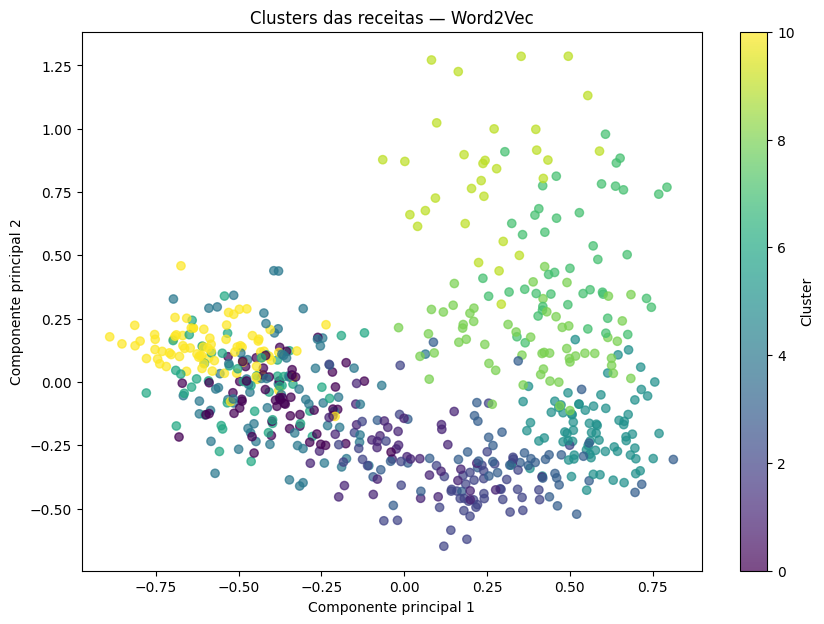

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Vetores utilizados pelo Word2Vec
matriz_visualizacao = embeddings_word2vec

# Redução para duas dimensões
pca = PCA(
    n_components=2,
    random_state=42
)

coordenadas = pca.fit_transform(
    matriz_visualizacao
)

# Clusters calculados anteriormente pelo K-Means
clusters = df_modelos[
    "cluster_word2vec"
]

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    coordenadas[:, 0],
    coordenadas[:, 1],
    c=clusters,
    alpha=0.7
)

plt.title(
    "Clusters das receitas — Word2Vec"
)

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.show()

## 23. Comparação de busca

A mesma consulta será executada nos quatro métodos, retornando um ranking Top-5.

Neste momento, a avaliação da busca será **manual**, observando quais receitas foram recuperadas, em que ordem aparecem e se são semanticamente adequadas à consulta.

> **Ponto para validar com o professor:** confirmar se a comparação qualitativa dos rankings é suficiente ou se deve ser adotada posteriormente uma métrica quantitativa de recuperação.


In [ ]:
def preparar_consulta_classica(
    consulta
):
    tokens_consulta = word_tokenize(
        consulta,
        language="portuguese"
    )

    tokens_consulta = normalizar_tokens(
        tokens_consulta
    )

    return remover_stopwords(
        tokens_consulta
    )


def representar_consulta_word2vec(
    consulta
):
    tokens = preparar_consulta_classica(
        consulta
    )

    conhecidos = [
        token
        for token in tokens
        if token in modelo_w2v.wv
    ]

    oov = [
        token
        for token in tokens
        if token not in modelo_w2v.wv
    ]

    if not conhecidos:
        return None, conhecidos, oov

    vetor = np.mean(
        [
            modelo_w2v.wv[token]
            for token in conhecidos
        ],
        axis=0
    )

    return vetor, conhecidos, oov


def buscar_top_k(
    vetor_consulta,
    matriz_documentos,
    metodo,
    k=5
):
    similaridades_busca = (
        cosine_similarity(
            vetor_consulta,
            matriz_documentos
        )[0]
    )

    indices = np.argsort(
        similaridades_busca
    )[::-1][:k]

    resultado = df_modelos.loc[
        indices,
        [
            "Título",
            "Categorias"
        ]
    ].copy()

    resultado.insert(
        0,
        "Método",
        metodo
    )

    resultado.insert(
        1,
        "Posição",
        range(1, len(resultado) + 1)
    )

    resultado["Similaridade"] = (
        similaridades_busca[indices]
    )

    return resultado


def comparar_busca(
    consulta,
    k=5
):
    tokens_consulta = (
        preparar_consulta_classica(
            consulta
        )
    )

    resultados = []

    # BoW
    vetor_bow = (
        bow_vectorizer.transform(
            [tokens_consulta]
        )
    )

    resultados.append(
        buscar_top_k(
            vetor_bow,
            bow_matrix,
            "BoW",
            k
        )
    )

    # TF-IDF
    vetor_tfidf = (
        tfidf_vectorizer.transform(
            [tokens_consulta]
        )
    )

    resultados.append(
        buscar_top_k(
            vetor_tfidf,
            tfidf_matrix,
            "TF-IDF",
            k
        )
    )

    # Word2Vec
    vetor_w2v, conhecidos, oov = (
        representar_consulta_word2vec(
            consulta
        )
    )

    print(
        "Word2Vec — tokens conhecidos:",
        conhecidos or "Nenhum"
    )
    print(
        "Word2Vec — OOV:",
        oov or "Nenhum"
    )

    if vetor_w2v is not None:
        resultados.append(
            buscar_top_k(
                np.asarray(
                    vetor_w2v
                ).reshape(1, -1),
                embeddings_word2vec,
                "Word2Vec",
                k
            )
        )

    # BERTimbau
    vetor_bert = gerar_embeddings_bert(
        [consulta]
    )

    resultados.append(
        buscar_top_k(
            vetor_bert,
            embeddings_bert,
            "BERT",
            k
        )
    )

    return pd.concat(
        resultados,
        ignore_index=True
    )


In [ ]:
CONSULTAS_TESTE = [
    "bolo fubá",
    "frango com batata",
    "risoto de carne",
]

for consulta in CONSULTAS_TESTE:
    print(
        f"\n{'=' * 70}\n"
        f"Consulta: {consulta}\n"
        f"{'=' * 70}"
    )

    display(
        comparar_busca(
            consulta,
            k=5
        )
    )



Consulta: bolo fubá
Word2Vec — tokens conhecidos: ['bolo', 'fubá']
Word2Vec — OOV: Nenhum


,Método,Posição,Título,Categorias,Similaridade
0,BoW,1,Bolo de fubá de liquidificador cremoso sem trigo e assado na airfryer,[BOLOS E TORTAS],0.505247
1,BoW,2,Bolo de fubá simples,[BOLOS E TORTAS],0.483494
2,BoW,3,Bolo de fubá cremoso,[BOLOS E TORTAS],0.410997
3,BoW,4,Bolo de fubá com goiabada,[BOLOS E TORTAS],0.377415
4,BoW,5,Broa de fubá de liquidificador,[MASSAS],0.316228
5,TF-IDF,1,Bolo de fubá simples,[BOLOS E TORTAS],0.658288
6,TF-IDF,2,Bolo de fubá de liquidificador cremoso sem trigo e assado na airfryer,[BOLOS E TORTAS],0.614603
7,TF-IDF,3,Bolo de fubá cremoso,[BOLOS E TORTAS],0.536338
8,TF-IDF,4,Bolo de fubá com goiabada,[BOLOS E TORTAS],0.438242
9,TF-IDF,5,Broa de fubá de liquidificador,[MASSAS],0.384926



Consulta: frango com batata
Word2Vec — tokens conhecidos: ['frango', 'batata']
Word2Vec — OOV: Nenhum


,Método,Posição,Título,Categorias,Similaridade
0,BoW,1,Frango cremoso,[AVES],0.492518
1,BoW,2,Frango com batata,[AVES],0.482451
2,BoW,3,Frango com Catupiri e batata palha da tia Gracia,"[AVES, SOPAS]",0.461566
3,BoW,4,Frango assado na panela de pressão,[AVES],0.414039
4,BoW,5,Fricassê de frango,[AVES],0.396297
5,TF-IDF,1,Frango cremoso,[AVES],0.470148
6,TF-IDF,2,Frango com batata,[AVES],0.436886
7,TF-IDF,3,Frango com Catupiri e batata palha da tia Gracia,"[AVES, SOPAS]",0.394037
8,TF-IDF,4,Fricassê de frango,[AVES],0.392697
9,TF-IDF,5,Frango assado na panela de pressão,[AVES],0.382928



Consulta: risoto de carne
Word2Vec — tokens conhecidos: ['risoto', 'carne']
Word2Vec — OOV: Nenhum


,Método,Posição,Título,Categorias,Similaridade
0,BoW,1,Carne de panela de pressão,[CARNES],0.346410
1,BoW,2,Rocambole de carne moída maravilhoso,[CARNES],0.341882
2,BoW,3,Cupim assado,[CARNES],0.317500
3,BoW,4,Sopa eslava,[SOPAS],0.310087
4,BoW,5,Carne louca de festa,[CARNES],0.308901
5,TF-IDF,1,Carne de panela de pressão,[CARNES],0.232630
6,TF-IDF,2,Sopa eslava,[SOPAS],0.210091
7,TF-IDF,3,Rocambole de carne moída maravilhoso,[CARNES],0.207310
8,TF-IDF,4,Carne louca de festa,[CARNES],0.205795
9,TF-IDF,5,Strogonoff de carne,[CARNES],0.204015


## 24. Síntese dos resultados

A tabela abaixo resume a comparação proposta em aula.

- **Similaridade:** o ✓ é definido pela maior coerência média no Top-5.
- **Clusters:** o ✓ é definido pelo maior Silhouette Score.
- **Busca:** o resultado permanece para avaliação manual dos rankings até a validação desse critério com o professor.


In [ ]:
metodos = [
    "BoW",
    "TF-IDF",
    "Word2Vec",
    "BERT",
]

resumo_final = pd.DataFrame(
    index=[
        "Similaridade",
        "Clusters",
        "Busca",
    ],
    columns=metodos,
)

scores_similaridade = (
    resultado_similaridade
    .set_index("Método")[
        "Coerência Top-5"
    ]
)

scores_clusters = (
    resultado_clusters
    .set_index("Método")[
        "Silhouette"
    ]
)

for metodo in metodos:
    valor_sim = (
        f"{scores_similaridade[metodo]:.3f}"
    )

    if metodo == MELHOR_SIMILARIDADE:
        valor_sim += " ✓"

    resumo_final.loc[
        "Similaridade",
        metodo
    ] = valor_sim

    valor_cluster = (
        f"{scores_clusters[metodo]:.3f}"
    )

    if metodo == MELHOR_CLUSTER:
        valor_cluster += " ✓"

    resumo_final.loc[
        "Clusters",
        metodo
    ] = valor_cluster

    resumo_final.loc[
        "Busca",
        metodo
    ] = "avaliar ranking"

display(resumo_final)


,BoW,TF-IDF,Word2Vec,BERT
Similaridade,0.550,0.607 ✓,0.563,0.441
Clusters,0.056,0.036,0.101 ✓,0.062
Busca,avaliar ranking,avaliar ranking,avaliar ranking,avaliar ranking
